# 04 — Interest Rate Swap : évaluation et gestion du risque

Ce notebook construit, évalue et couvre un **swap de taux d'intérêt** (Interest Rate Swap, IRS) du point de vue d'un **payeur du taux fixe**.

Contenu :
1. Construction du calendrier de paiement et pricing d'un swap 5 ans payeur.
2. Vérification des relations fondamentales : jambe fixe, jambe variable, formule $N \cdot A \cdot (S - K)$.
3. Visualisation des flux et de la valeur du swap.
4. Sensibilité au taux fixe $K$ — linéarité et annulation au taux au pair $S$.
5. **DV01 du swap** : sensibilité à un choc parallèle sur la courbe.
6. Équivalence swap payeur ↔ (nominal − obligation à taux fixe).
7. **Key-rate DV01** : répartition du risque par pilier de courbe.
8. Application : couverture d'une obligation 7 ans par un swap, et analyse du **risque de pente**.
9. Sensibilité du swap à la courbe US réelle à différentes dates.

**Formules clés :**
- Taux swap au pair : $S = \dfrac{1 - DF(T)}{A}$ où $A = \sum_i DF(t_i)$
- Valeur payeur : $V_{\text{payer}} = N \cdot A \cdot (S - K)$
- DV01 payeur : $N \cdot A \cdot 1\text{bp}$

## 1. Imports et configuration

On ajoute la racine du projet au chemin Python pour importer :
- `src.bonds` : `cashflows`.
- `src.curve` : `bootstrap_par_curve`, `discount_factor`, `price_with_curve`.
- `src.risk` : `dv01_curve`, `key_rate_dv01`.
- `src.swap` : `swap_schedule`, `annuity`, `par_swap_rate`, `swap_legs`, `swap_value`, `swap_dv01`, `swap_key_rate_dv01`.

On construit une courbe synthétique de taux au pair (maturités 1 à 10 ans, de 2.5 % à 3.7 %) — la même que dans le notebook 02 — pour servir de référence tout au long du notebook.

In [4]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / "src" / "__init__.py").is_file():
    project_root = project_root.parent
if not (project_root / "src" / "__init__.py").is_file():
    raise FileNotFoundError("Could not locate the project root containing src/__init__.py")
sys.path.insert(0, str(project_root))

from src.bonds import cashflows
from src.curve import bootstrap_par_curve, discount_factor, price_with_curve
from src.risk import dv01_curve, key_rate_dv01
from src.swap import (swap_schedule, annuity, par_swap_rate, swap_legs, swap_value,
                      swap_dv01, swap_key_rate_dv01)

mats = np.arange(1, 11)
par = np.array([0.025, 0.027, 0.029, 0.031, 0.0325, 0.034, 0.035, 0.036, 0.0365, 0.037])
_, zeros = bootstrap_par_curve(mats, par)

## 2. Décomposition des flux d'un swap payeur

On considère un swap **payeur du fixe** :
- Nominal : 10 M€
- Taux fixe payé : $K = 3{,}50\%$
- Maturité : 5 ans
- Fréquence : annuelle

Pour chaque date $t_i$ de paiement, on calcule :
- **DF** : facteur d'actualisation depuis la courbe zéro-coupon.
- **forward** : taux forward implicite de $t_{i-1}$ à $t_i$.
- **Fixe payé** : $N \cdot K$ (constant).
- **Variable reçu (attendu)** : $N \cdot f_{t_{i-1}, t_i}$ (le taux forward est l'estimation neutre au risque).
- **Net** : variable − fixe.
- **PV du net** : $DF(t_i) \cdot \text{net}$.

La **valeur du swap** est la somme des PV du net. Chaque PV est la contribution de la date $t_i$ à la valeur totale.

Observations attendues :
- Le tableau permet de **décomposer** la valeur du swap flux par flux.
- On identifie immédiatement si le swap est en gain ou en perte.

In [5]:
N, K, T = 10_000_000, 0.035, 5            # payeur du fixe 3,50 % sur 5 ans
pay = swap_schedule(T)

df = discount_factor(pay, mats, zeros)
fwd = discount_factor(pay - 1, mats, zeros) / df - 1
fixed = np.full(len(pay), N * K)
floating = N * fwd
net = floating - fixed

table = pd.DataFrame({"t": pay, "DF": df, "forward": fwd,
                      "fixe payé": fixed, "variable reçu (attendu)": floating,
                      "net": net, "PV du net": net * df})
display(table.round(4))
print("Valeur du swap (somme des PV) :", round(table["PV du net"].sum(), 2))

,t,DF,forward,fixe payé,variable reçu (attendu),net,PV du net
0,1.0,0.9756,0.0250,350000.0,250000.0000,-100000.0000,-97560.9756
1,2.0,0.9481,0.0291,350000.0,290581.1623,-59418.8377,-56332.6763
2,3.0,0.9176,0.0332,350000.0,331928.1654,-18071.8346,-16582.7708
3,4.0,0.8845,0.0374,350000.0,374245.8010,24245.8010,21445.4348
4,5.0,0.8512,0.0391,350000.0,390652.6642,40652.6642,34605.4504


Valeur du swap (somme des PV) : -114425.54


## 3. Relations fondamentales du swap

On calcule séparément les deux jambes du swap :
- **Jambe fixe** : valeur actuelle des $N \cdot K$ actualisés = $N \cdot K \cdot A$.
- **Jambe variable** : valeur actuelle des forwards actualisés.

La théorie indique trois relations qu'on vérifie numériquement :

1. **Jambe variable = $N(1 - DF(T))$** : une jambe variable qui paie le taux forward vaut exactement le nominal moins le zéro-coupon final. C'est une propriété classique de non-arbitrage.

2. **Taux swap au pair** : $S = \frac{1 - DF(T)}{A}$. Il rend la valeur du swap nulle. Il coïncide avec le taux au pair de la courbe quand les fréquences correspondent.

3. **Formule compacte** : $V_{\text{payer}} = N \cdot A \cdot (S - K)$. C'est l'identité que tout desk de taux utilise pour valoriser les swaps.

Vérifier ces égalités à la précision numérique près est un **test de cohérence** du pricing.

In [6]:
fixed_leg, float_leg = swap_legs(N, K, pay, mats, zeros)
S, A = par_swap_rate(pay, mats, zeros), annuity(pay, mats, zeros)

print(f"Jambe fixe     : {fixed_leg:,.0f}")
print(f"Jambe variable : {float_leg:,.0f}   | N(1 - DF) = {N * (1 - df[-1]):,.0f}")
print(f"Taux swap 5 ans S = {S:.4%}   | taux au pair 5 ans (étape 2) = {par[4]:.4%}")
print(f"Valeur payeur  : {swap_value(N, K, pay, mats, zeros):,.0f}   | N*A*(S-K) = {N * A * (S - K):,.0f}")

Jambe fixe     : 1,601,958
Jambe variable : 1,487,532   | N(1 - DF) = 1,487,532
Taux swap 5 ans S = 3.2500%   | taux au pair 5 ans (étape 2) = 3.2500%
Valeur payeur  : -114,426   | N*A*(S-K) = -114,426


## 4. Visualisation des flux et de la valeur du swap

Deux graphiques :
- **À gauche** : les flux bruts — fixe payé (constant) vs variable reçu (croissant car la courbe est ascendante). On voit que les flux variables dépassent les flux fixes à partir de l'année 4.
- **À droite** : le **PV net** par date de paiement, coloré en vert (gain) ou rouge (perte). La valeur totale du swap est la somme de ces barres.

**Message clé** : sur une courbe ascendante, un payeur du fixe à un taux inférieur au taux au pair est en perte sur les premières années, puis en gain sur les dernières — mais l'effet d'actualisation domine souvent les premières années.

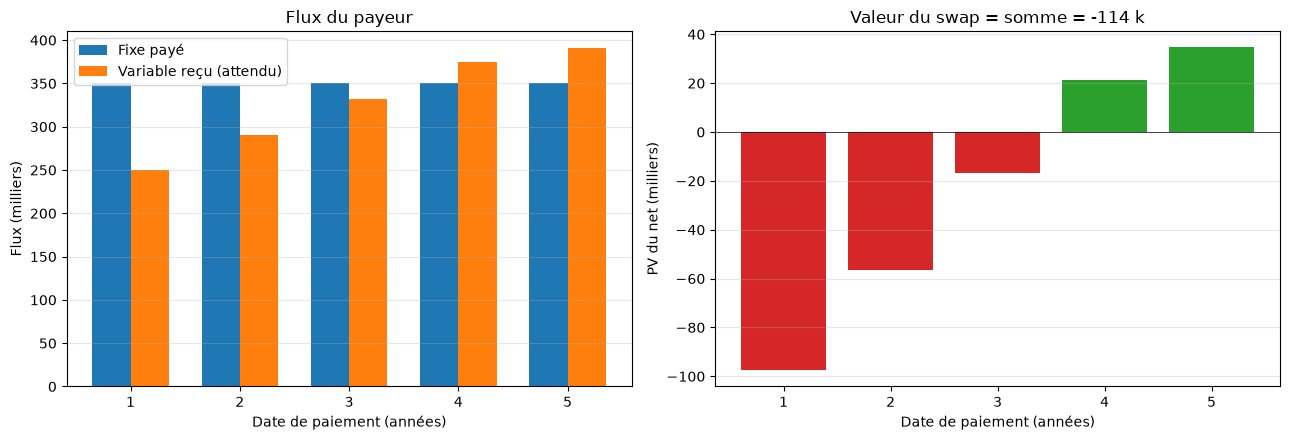

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

w = 0.35
axes[0].bar(pay - w / 2, fixed / 1e3, w, label="Fixe payé")
axes[0].bar(pay + w / 2, floating / 1e3, w, label="Variable reçu (attendu)")
axes[0].set_xlabel("Date de paiement (années)"); axes[0].set_ylabel("Flux (milliers)")
axes[0].set_title("Flux du payeur"); axes[0].legend()

axes[1].bar(pay, net * df / 1e3, color=["tab:red" if v < 0 else "tab:green" for v in net])
axes[1].axhline(0, color="k", lw=0.5)
axes[1].set_xlabel("Date de paiement (années)"); axes[1].set_ylabel("PV du net (milliers)")
axes[1].set_title(f"Valeur du swap = somme = {net @ df / 1e3:,.0f} k")

for ax in axes: ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

## 5. Valeur du swap en fonction du taux fixe K

On trace la valeur du swap pour :
- Le **payeur du fixe** (courbe croissante en K).
- Le **receveur du fixe** (courbe décroissante, symétrique).

Le point d'annulation est **le taux au pair $S$** : c'est par construction la valeur de $K$ qui rend le swap nul à l'initiation.

**Observations attendues :**
- La relation est **linéaire** en $K$ : $V = N \cdot A \cdot (S - K)$.
- Payeur et receveur sont **symétriques** par rapport à l'axe des abscisses.
- La pente vaut $N \cdot A$, ce qui est directement lié au DV01 du swap.

**Message clé** : contrairement à une obligation (relation convexe), un swap a une valeur **linéaire** en $K$ — c'est un instrument de premier ordre.

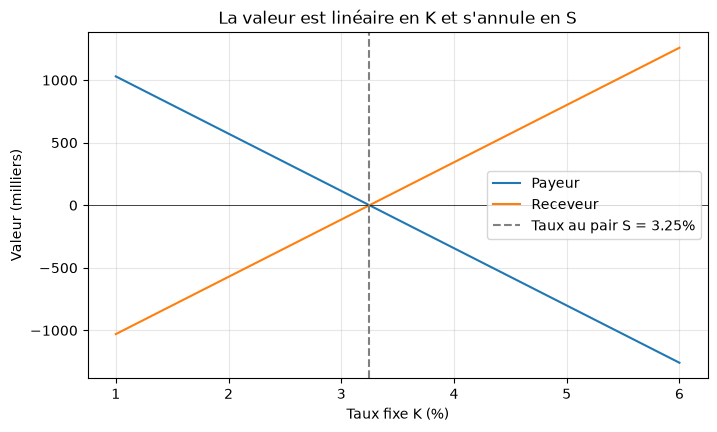

In [8]:
Ks = np.linspace(0.01, 0.06, 100)
v_payer = [swap_value(N, k, pay, mats, zeros) for k in Ks]
v_recv = [swap_value(N, k, pay, mats, zeros, payer=False) for k in Ks]

plt.figure(figsize=(8, 4.5))
plt.plot(Ks * 100, np.array(v_payer) / 1e3, label="Payeur")
plt.plot(Ks * 100, np.array(v_recv) / 1e3, label="Receveur")
plt.axhline(0, color="k", lw=0.5)
plt.axvline(S * 100, color="gray", ls="--", label=f"Taux au pair S = {S:.2%}")
plt.xlabel("Taux fixe K (%)"); plt.ylabel("Valeur (milliers)")
plt.title("La valeur est linéaire en K et s'annule en S")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## 6. Sensibilité aux taux : DV01 du swap

On applique un **choc parallèle** sur toute la courbe zéro-coupon, de −200 bp à +200 bp, et on trace la valeur exacte du swap payeur.

En parallèle, on trace l'approximation **linéaire** obtenue par le DV01 (droite tangente).

**Observations attendues :**
- Le payeur du fixe **gagne quand les taux montent** : intuitif, il paie un taux fixe devenu "bas" par rapport au marché.
- L'approximation par DV01 est **quasi-parfaite** même pour des chocs de ±200 bp.
- La pente de la droite est le DV01 du swap, qui vaut $N \cdot A \cdot 1\text{bp}$.

**Message clé** : les swaps ont une **sensibilité de premier ordre** dominante, sans effet convexe notable — contrairement aux options.

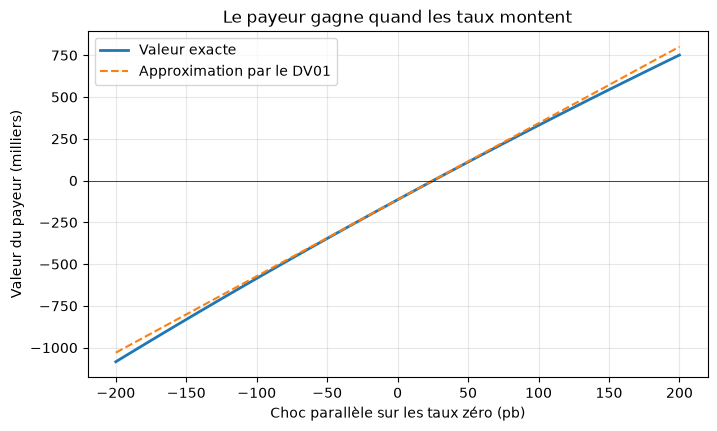

DV01 payeur : 4,577 par pb | N*A*1pb = 4,577


In [9]:
shifts_bp = np.linspace(-200, 200, 81)
v = np.array([swap_value(N, K, pay, mats, zeros + b / 1e4) for b in shifts_bp])
v0 = swap_value(N, K, pay, mats, zeros)
lin = v0 + swap_dv01(N, K, pay, mats, zeros) * shifts_bp

plt.figure(figsize=(8, 4.5))
plt.plot(shifts_bp, v / 1e3, label="Valeur exacte", lw=2)
plt.plot(shifts_bp, lin / 1e3, "--", label="Approximation par le DV01")
plt.axhline(0, color="k", lw=0.5)
plt.xlabel("Choc parallèle sur les taux zéro (pb)"); plt.ylabel("Valeur du payeur (milliers)")
plt.title("Le payeur gagne quand les taux montent")
plt.legend(); plt.grid(alpha=0.3); plt.show()

print(f"DV01 payeur : {swap_dv01(N, K, pay, mats, zeros):,.0f} par pb | N*A*1pb = {N * A * 1e-4:,.0f}")

## 7. Équivalence swap ↔ obligation synthétique

Un swap payeur du fixe est **équivalent** à une position :
- **Longue** d'une obligation à taux flottant (valant toujours le nominal).
- **Courte** d'une obligation à taux fixe $K$ et maturité $T$.

Autrement dit : $V_{\text{payeur}} = N - \text{Prix}_{\text{obligation à taux } K}$.

Cette cellule vérifie cette **équivalence de pricing** à la précision numérique près. C'est une identité fondamentale, utile pour :
- calculer le DV01 d'un swap à partir de celui d'une obligation ;
- comprendre l'exposition de crédit d'un swap ;
- relier les marchés obligataire et swap.

**Message clé** : tout swap peut être répliqué par un portefeuille long-short de deux obligations.

In [10]:
t, cf = cashflows(100, K, T)
bond_value = N / 100 * price_with_curve(t, cf, mats, zeros)
print(f"Valeur payeur            : {swap_value(N, K, pay, mats, zeros):,.2f}")
print(f"Nominal - obligation à K : {N - bond_value:,.2f}")

Valeur payeur            : -114,425.54
Nominal - obligation à K : -114,425.54


## 8. Profils de risque : obligation vs swap

On compare les **key-rate DV01** d'une obligation 7 ans coupon 5 % et d'un swap payeur 7 ans à taux au pair.

Pour un choc de +1 bp sur chaque pilier de courbe, on mesure le P&L de chaque instrument :
- **Obligation longue** : P&L négatif sur chaque pilier (le prix baisse quand les taux montent).
- **Swap payeur** : P&L positif sur chaque pilier (le payeur bénéficie de la hausse).

**Observations attendues :**
- Les deux profils sont **presque opposés** (symétriques par rapport à 0).
- Le swap a un profil **plus concentré sur les piliers longs** (les coupons et le nominal du swap sont répartis sur toute la maturité).
- Le swap a un **profil plus régulier** (les flux sont comparables en taille), alors que l'obligation a un profil dominé par le gros flux terminal.

**Message clé** : le swap est un outil de couverture **naturel** pour une obligation, mais la correspondance n'est pas parfaite — surtout en cas de mouvement non parallèle de la courbe.

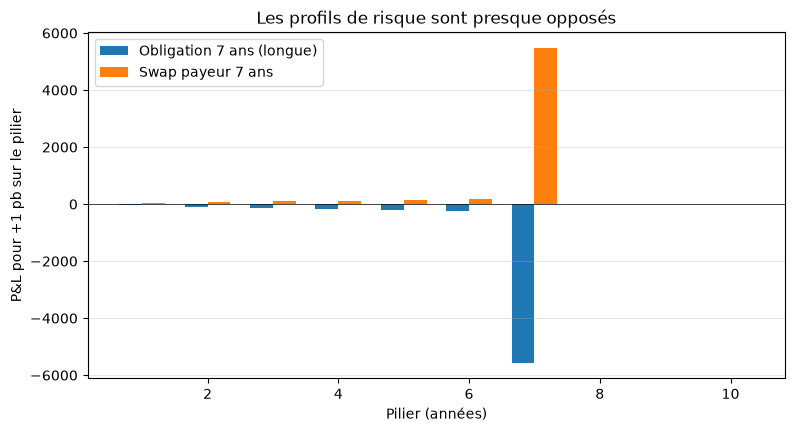

In [11]:
t7, cf7 = cashflows(100, 0.05, 7)
N_bond = 10_000_000
pay7 = swap_schedule(7)
K7 = par_swap_rate(pay7, mats, zeros)

kr_swap = swap_key_rate_dv01(N_bond, K7, pay7, mats, zeros)            # P&L pour +1 pb
kr_bond = -key_rate_dv01(t7, cf7, mats, zeros) * N_bond / 100          # on passe en P&L

w = 0.35
plt.figure(figsize=(9, 4.5))
plt.bar(mats - w / 2, kr_bond, w, label="Obligation 7 ans (longue)")
plt.bar(mats + w / 2, kr_swap, w, label="Swap payeur 7 ans")
plt.axhline(0, color="k", lw=0.5)
plt.xlabel("Pilier (années)"); plt.ylabel("P&L pour +1 pb sur le pilier")
plt.title("Les profils de risque sont presque opposés")
plt.legend(); plt.grid(alpha=0.3, axis="y"); plt.show()

## 9. Couverture DV01-neutre et risque de pente

On illustre un cas classique de gestion de portefeuille :

- **Position longue** : 10 M€ de nominal sur une obligation 7 ans coupon 5 %.
- **Couverture** : on cherche le nominal d'un swap payeur (7 ans ou 10 ans) qui **neutralise le DV01 parallèle** de l'obligation.

On simule ensuite quatre scénarios de marché :
- Parallèle +50 bp
- Parallèle −100 bp
- **Pentification** (2 ans −25 bp, 10 ans +25 bp en linéaire)
- **Aplatissement** (inverse)

**Observations attendues :**
- Le DV01 parallèle est **bien neutralisé** dans les deux cas (couverture 7 ou 10 ans).
- En cas de **pentification** ou d'**aplatissement**, la couverture par swap 7 ans est meilleure que par swap 10 ans : le P&L résiduel est plus faible.
- Cela s'explique par la **proximité des profils de key-rate DV01** (7 ans vs 7 ans).

**Message clé** : être DV01-neutre ne suffit pas — il faut aussi **matcher les profils de key-rate**. Un swap de maturité proche de l'obligation minimise le risque de pente résiduel.

In [12]:
def bond_pnl(shock):
    return N_bond / 100 * (price_with_curve(t7, cf7, mats, zeros + shock)
                           - price_with_curve(t7, cf7, mats, zeros))

scenarios = {
    "parallèle +50 pb": np.full(10, 0.005),
    "parallèle -100 pb": np.full(10, -0.01),
    "pentification": np.linspace(-0.0025, 0.0025, 10),
    "aplatissement": np.linspace(0.0025, -0.0025, 10),
}
one_bp = np.full(10, 1e-4)

def hedge_table(swap_T):
    pay_h = swap_schedule(swap_T)
    K_h = par_swap_rate(pay_h, mats, zeros)
    swap_pnl = lambda notional, s: (swap_value(notional, K_h, pay_h, mats, zeros + s)
                                    - swap_value(notional, K_h, pay_h, mats, zeros))
    notional = -bond_pnl(one_bp) / swap_pnl(1.0, one_bp)       # neutralise le DV01 parallèle
    pnl = {name: bond_pnl(s) + swap_pnl(notional, s) for name, s in scenarios.items()}
    return notional, pnl

res = {}
for swap_T in [7, 10]:
    notional, pnl = hedge_table(swap_T)
    print(f"Nominal du swap payeur {swap_T} ans pour couvrir : {notional:,.0f}")
    res[f"couvert par swap {swap_T} ans"] = pnl

pd.DataFrame(res).round(0)

Nominal du swap payeur 7 ans pour couvrir : 10,566,574
Nominal du swap payeur 10 ans pour couvrir : 7,860,402


,couvert par swap 7 ans,couvert par swap 10 ans
parallèle +50 pb,-73.0,-2031.0
parallèle -100 pb,-322.0,-9204.0
pentification,3536.0,97499.0
aplatissement,-3539.0,-100889.0


## 10. Application : sensibilité à la courbe US réelle

On reprend le swap payeur 5 ans à $K = 3{,}50\%$ et on l'évalue sur la **courbe US Treasury réelle** à trois dates :
- **Juillet 2021** : environnement de taux très bas post-COVID.
- **Juillet 2023** : cycle de hausses agressives de la Fed.
- **Date la plus récente** : état actuel de la courbe.

Pour chaque date, on calcule :
- Le taux swap au pair $S_{5\text{ans}}$.
- La valeur du swap payeur à $K = 3{,}50\%$.
- Le DV01.

**Observations attendues :**
- En **2021** ($S \approx 0{,}9\%$), le payeur à 3,5 % est **très en perte** : il paie un taux bien au-dessus du marché.
- En **2023** ($S \approx 4{,}2\%$), le swap est en **gain** : le taux fixe payé est inférieur au marché.
- Le **DV01** est plus élevé en 2021 qu'en 2023 car la valeur du swap (et donc sa durée en euros) est plus grande en valeur absolue.

**Message clé** : la valeur et le risque d'un swap évoluent **fortement** avec la courbe — le DV01 n'est pas une constante.

In [14]:
from src.curve import par_on_annual_grid

curves = pd.read_csv("../data/us_par_yields.csv", index_col=0, parse_dates=True)
curves.columns = curves.columns.astype(int)

rows = []
for d in ["2021-07-01", "2023-07-03", str(curves.index[-1].date())]:
    row = curves.loc[:d].iloc[-1]
    m_us, p_us = par_on_annual_grid(row.index.values, row.values)
    _, z_us = bootstrap_par_curve(m_us, p_us)
    s5 = par_swap_rate(swap_schedule(5), m_us, z_us)
    rows.append({"date": row.name.date(), "S 5 ans": s5,
                 "valeur payeur à K=3,5 %": swap_value(N, 0.035, swap_schedule(5), m_us, z_us),
                 "DV01 (P&L +1 pb)": swap_dv01(N, 0.035, swap_schedule(5), m_us, z_us)})
pd.DataFrame(rows)

,date,S 5 ans,"valeur payeur à K=3,5 %",DV01 (P&L +1 pb)
0,2021-07-01,0.008920,-1.280374e+06,5247.024652
1,2023-07-03,0.042339,3.218521e+05,4337.116166
2,2026-10-09,0.050830,6.858342e+05,4128.310629
